In [1]:
from pathlib import Path

# ==================================================
# Input parameters (shared by every cell below)
# ==================================================

L_angstrom = 300.0

target_fZ_GHz = 3     # fixed Zeeman frequency (GHz)
E_dc_Vum = 6.0        # dc gate field (V/um), as in the EDSR script
E_dc_dir = "y"        # "y" -> E_y^dc, "z" -> E_z^dc
E_ac_Vum = 0.001
f_orb_GHz = 100.0

# Directory containing the numerical .dat files and directory for saved plots.
data_dir = Path(".")
output_dir = Path("export_data")
output_dir.mkdir(parents=True, exist_ok=True)

# Convert the cross-sectional length to nm for display.
L_nm = L_angstrom / 10.0


Loaded f_Z = 3 GHz: EDSR_sphere_map_fz_3_Eth83.20dc_6.npz
Saved comparison plots as export_data\fixed_Zeeman_comparison_fz_3_Eth83.2dc_6_3x3.png/.pdf/.svg


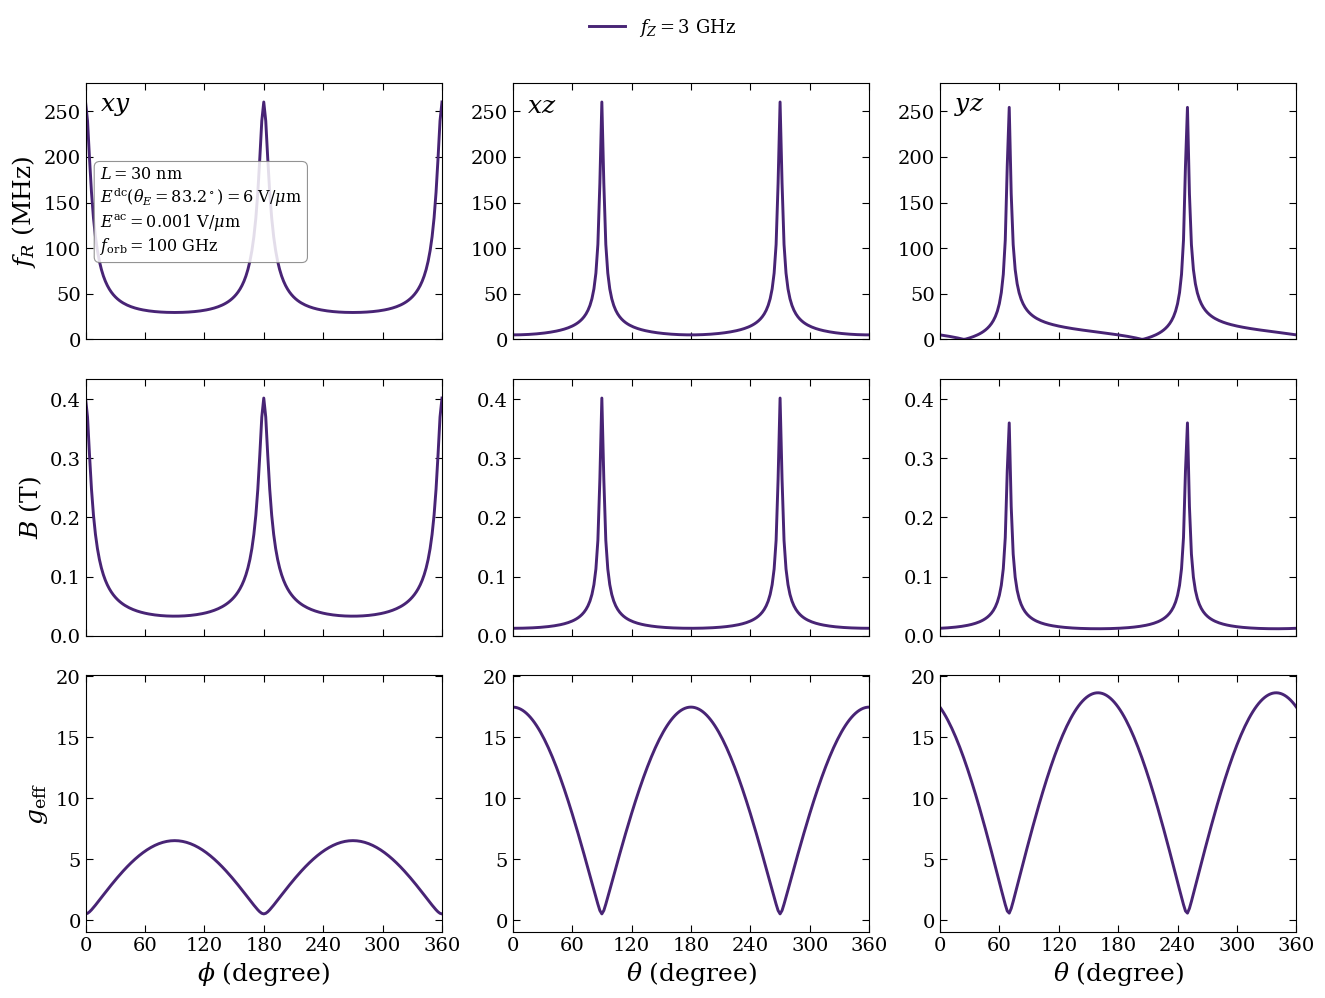

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Direction of E^dc in the y-z plane, measured from +y (0 -> E_y, 90 -> E_z).
# Set to None to use E_dc_dir ("y"/"z") instead.
E_dc_theta = 83.2


# ==================================================
# Data-file structure
#
#  0: angle_deg
#
#  1: g_xy
#  2: B_xy_T
#  3: fR_xy_MHz
#
#  4: g_xz
#  5: B_xz_T
#  6: fR_xz_MHz
#
#  7: g_yz
#  8: B_yz_T
#  9: fR_yz_MHz
# ==================================================


def load_fixed_zeeman_data(filename):
    """Load one fixed-Zeeman angular-sweep data file."""

    data = np.loadtxt(filename, comments="#")

    if data.ndim != 2 or data.shape[1] < 10:
        raise ValueError(
            f"{filename} must contain at least 10 columns:\n"
            "angle, g_xy, B_xy, fR_xy, "
            "g_xz, B_xz, fR_xz, "
            "g_yz, B_yz, fR_yz"
        )

    return {
        "angle": data[:, 0],
        "g_xy": data[:, 1],
        "B_xy": data[:, 2],
        "fR_xy": data[:, 3],
        "g_xz": data[:, 4],
        "B_xz": data[:, 5],
        "fR_xz": data[:, 6],
        "g_yz": data[:, 7],
        "B_yz": data[:, 8],
        "fR_yz": data[:, 9],
    }


def numerical_filename(fZ_GHz):
    """Filename written by main_EDSR_fixed_Zeeman_angle_sweep.py:
    numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fZ}_E{dir}dc_{E}.dat
    (tries the int/float spellings of fZ and E, e.g. 5 / 5.0 and 6.0 / 6)."""
    fz_forms = {f"{fZ_GHz:g}", f"{float(fZ_GHz)}"}
    e_forms = {f"{float(E_dc_Vum)}", f"{E_dc_Vum:g}"}
    candidates = [
        data_dir / f"numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fz}_E{E_dc_dir}dc_{e}.dat"
        for fz in sorted(fz_forms) for e in sorted(e_forms)
    ]
    for c in candidates:
        if c.is_file():
            return c
    return candidates[0]


def sphere_map_filename(fZ_GHz):
    """Sphere map written by main_EDSR_sphere_map.py for E^dc at angle E_dc_theta from +y."""
    return data_dir / f"EDSR_sphere_map_fz_{fZ_GHz:g}_Eth{E_dc_theta:.2f}dc_{E_dc_Vum:g}.npz"


def load_from_sphere_map(filename):
    """Extract the xy, xz, yz plane cuts (0-360 deg) from a (theta, phi) sphere map.

    xy: theta = 90, angle = phi.
    xz / yz: angle = polar theta in the plane phi = 0 / 90; for theta > 180 use
    the symmetry (theta, phi) = (360 - theta, phi + 180).
    """
    m = np.load(filename)
    th, ph = m["theta_deg"], m["phi_deg"]
    fields = {"g": m["g_eff"], "B": m["B_T"], "fR": m["fR_MHz"]}

    def at(F, theta0=None, phi0=None):
        if theta0 is not None:
            return F[np.argmin(abs(th - theta0)), :]
        return F[:, np.argmin(abs(ph - phi0))]

    angle = np.arange(0.0, 360.0 + 1e-9, 2.0)
    result = {"angle": angle}
    for q, F in fields.items():
        result[f"{q}_xy"] = np.interp(angle, ph, at(F, theta0=90.0))
        for plane, phi0 in (("xz", 0.0), ("yz", 90.0)):
            lo, hi = at(F, phi0=phi0), at(F, phi0=phi0 + 180.0)
            # theta in [0, 180] on phi0, (180, 360] on phi0 + 180 with theta -> 360 - theta
            result[f"{q}_{plane}"] = np.where(
                angle <= 180.0,
                np.interp(angle, th, lo),
                np.interp(360.0 - angle, th, hi),
            )
    return result


def padded_limits(values, include_zero=False, padding=0.08):
    """Return common axis limits for several arrays."""

    minimum = min(np.nanmin(value) for value in values)
    maximum = max(np.nanmax(value) for value in values)

    if include_zero:
        minimum = min(0.0, minimum)
        maximum = max(0.0, maximum)

    span = maximum - minimum
    if np.isclose(span, 0.0):
        span = max(abs(maximum), 1.0)

    lower = 0.0 if include_zero and minimum >= 0.0 else minimum - padding * span
    upper = maximum + padding * span
    return lower, upper


# ==================================================
# Load the target-fZ dataset before plotting
# ==================================================

if E_dc_theta is not None:
    filename = sphere_map_filename(target_fZ_GHz)
    loader = load_from_sphere_map
else:
    filename = numerical_filename(target_fZ_GHz)
    loader = load_fixed_zeeman_data

if not filename.is_file():
    raise FileNotFoundError(
        f"Data file not found: {filename}\n"
        "Check target_fZ_GHz, E_dc_Vum, E_dc_dir / E_dc_theta, and data_dir."
    )

dataset = loader(filename)
print(f"Loaded f_Z = {target_fZ_GHz:g} GHz: {filename}")


# ==================================================
# Plot settings
# ==================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.8,
    "font.size": 15,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
})


# ==================================================
# Create one figure
#
# Columns: xy, xz, yz
# Rows:    fR, B, g
# ==================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(13.5, 10),
    sharex="col",
)

planes = ("xy", "xz", "yz")
row_quantities = ("fR", "B", "g")
color = plt.get_cmap("viridis")(0.10)

for row, quantity in enumerate(row_quantities):
    for col, plane in enumerate(planes):
        axes[row, col].plot(
            dataset["angle"],
            dataset[f"{quantity}_{plane}"],
            color=color,
            linewidth=2.1,
            label=fr"$f_Z={target_fZ_GHz:g}$ GHz",
        )


# ==================================================
# Panel labels and axis labels
# ==================================================

for col, plane in enumerate(planes):
    axes[0, col].text(
        0.04,
        0.96,
        fr"${plane}$",
        transform=axes[0, col].transAxes,
        fontsize=18,
        fontweight="bold",
        horizontalalignment="left",
        verticalalignment="top",
    )

axes[0, 0].set_ylabel(r"$f_R$ (MHz)", fontsize=18)
axes[1, 0].set_ylabel(r"$B$ (T)", fontsize=18)
axes[2, 0].set_ylabel(r"$g_{\mathrm{eff}}$", fontsize=18)

axes[2, 0].set_xlabel(r"$\phi$ (degree)", fontsize=18)
axes[2, 1].set_xlabel(r"$\theta$ (degree)", fontsize=18)
axes[2, 2].set_xlabel(r"$\theta$ (degree)", fontsize=18)


# ==================================================
# Common formatting and row-wise limits
# ==================================================

for ax in axes.flat:
    ax.set_xlim(0.0, 360.0)
    ax.set_xticks([0, 60, 120, 180, 240, 300, 360])
    ax.tick_params(
        direction="in",
        length=5,
        width=0.8,
        top=True,
        right=True,
        labelsize=14,
    )

# Use one y range across the three panels of each row so the rotation planes
# are directly comparable.
for row, quantity in enumerate(row_quantities):
    row_values = [dataset[f"{quantity}_{plane}"] for plane in planes]
    y_limits = padded_limits(
        row_values,
        include_zero=quantity in ("fR", "B"),
    )

    for col in range(3):
        axes[row, col].set_ylim(*y_limits)


# ==================================================
# Parameters and legend
# ==================================================

E_label = (
    fr"E^{{\mathrm{{dc}}}}(\theta_E={E_dc_theta:g}^\circ)" if E_dc_theta is not None
    else fr"E_{E_dc_dir}^{{\mathrm{{dc}}}}"
)
parameter_text = (
    fr"$L={L_nm:g}$ nm" "\n"
    fr"${E_label}={E_dc_Vum:g}$ V/$\mu$m" "\n"
    fr"$E^{{\mathrm{{ac}}}}={E_ac_Vum:g}$ V/$\mu$m" "\n"
    fr"$f_{{\mathrm{{orb}}}}={f_orb_GHz:g}$ GHz"
)

axes[0, 0].text(
    0.04,
    0.68,
    parameter_text,
    transform=axes[0, 0].transAxes,
    fontsize=11.5,
    horizontalalignment="left",
    verticalalignment="top",
    bbox={
        "boxstyle": "round,pad=0.35",
        "facecolor": "white",
        "edgecolor": "gray",
        "linewidth": 0.8,
        "alpha": 0.85,
    },
)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=1,
    frameon=False,
    fontsize=13,
)


# ==================================================
# Layout and save
# ==================================================

E_tag = f"th{E_dc_theta:g}" if E_dc_theta is not None else E_dc_dir
fz_tag = f"{target_fZ_GHz:g}_E{E_tag}dc_{E_dc_Vum:g}"
output_stem = output_dir / f"fixed_Zeeman_comparison_fz_{fz_tag}_3x3"

fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.95))

fig.savefig(f"{output_stem}.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{output_stem}.pdf", bbox_inches="tight")
fig.savefig(f"{output_stem}.svg", bbox_inches="tight")

print(f"Saved comparison plots as {output_stem}.png/.pdf/.svg")
plt.show()


In [5]:
for E_dir in E_dc_dirs:
    data = datasets[E_dir]
    ang, val = data["angle"], data["fR_yz"]
    half = ang <= 180
    a, v = ang[half], val[half]
    i = np.nanargmax(v)
    if 0 < i < len(v) - 1:  # parabolic refinement
        y0, y1, y2 = v[i-1], v[i], v[i+1]
        d = 0.5 * (y0 - y2) / (y0 - 2*y1 + y2)
        theta = a[i] + d * (a[1] - a[0])
        fmax = y1 - 0.25 * (y0 - y2) * d
    else:
        theta, fmax = a[i], v[i]
    print(f"{case_label(E_dir)}: max f_R = {fmax:.6g} MHz at θ = {theta:.2f}° (grid {a[i]:g}°)")


E_y^{\mathrm{dc}}: max f_R = 16.8216 MHz at θ = 0.00° (grid 0°)
E_z^{\mathrm{dc}}: max f_R = 196.812 MHz at θ = 90.00° (grid 90°)
E^{\mathrm{dc}}(\theta_E=83.2^\circ): max f_R = 255.096 MHz at θ = 69.81° (grid 70°)


Loaded EDSR_sphere_map_fz_3_Eth0.00dc_6.npz:  91 theta x 181 phi,  f_R = 2.27e-11 - 16.82 MHz
Loaded EDSR_sphere_map_fz_3_Eth90.00dc_6.npz:  91 theta x 181 phi,  f_R = 1.9e-13 - 196.8 MHz
Loaded EDSR_sphere_map_fz_3_Eth83.20dc_6.npz:  91 theta x 181 phi,  f_R = 0.139 - 260.2 MHz
Saved export_data/EDSR_sphere_map_fz_3_Edc_6_th0_th90_th83.2.png/.pdf


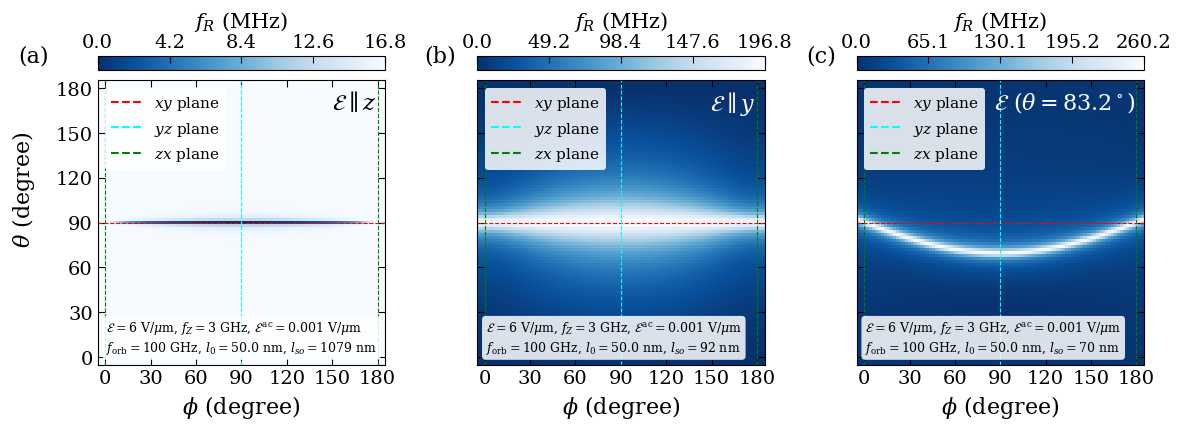

In [9]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


# ==================================================
# Input parameters
# ==================================================

# target_fZ_GHz = 3
# E_dc_Vum = 6.0        # dc gate field (V/um), as in main_EDSR_sphere_map.py
# data_dir = Path(".")
# output_dir = Path(".")

# panels (a), (b), (c): angle theta_E of E^dc in the y-z plane, measured from +y (0 -> E_y, 90 -> E_z)
E_dc_thetas = (0.0, 90.0, 83.2)
# E_dc_labels = (r"E_y^{\mathrm{dc}}", r"E_z^{\mathrm{dc}}", r"E^{\mathrm{dc}}(\theta_E=83.2^\circ)")


# ==================================================
# Load the maps
# ==================================================

maps = []
for E_dc_theta in E_dc_thetas:
    fname = data_dir / f"EDSR_sphere_map_fz_{target_fZ_GHz:g}_Eth{E_dc_theta:.2f}dc_{E_dc_Vum:g}.npz"
    d = np.load(fname)
    maps.append(dict(d))
    print(f"Loaded {fname}:  {len(d['theta_deg'])} theta x {len(d['phi_deg'])} phi,"
          f"  f_R = {np.nanmin(d['fR_MHz']):.3g} - {np.nanmax(d['fR_MHz']):.4g} MHz")


# ==================================================
# Plot settings
# ==================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.8,
    "font.size": 14,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
})

cmap_fR = plt.get_cmap("Blues_r").copy()
cmap_fR.set_bad("0.75")


pad_deg = 5.0     # show this much beyond phi = 0, 180 and theta = 0, 180 so the boundary lines are visible


def extend(m, pad=pad_deg + 1.0):
    """Pad the map beyond the plotted ranges using the symmetries of the sphere:
    phi is 360-periodic, and the direction (-theta, phi) = (theta, phi + 180),
    (180 + t, phi) = (180 - t, phi + 180)."""
    th, ph, F = m["theta_deg"], m["phi_deg"], m["fR_MHz"]
    Fu, n, dphi = F[:, :-1], len(ph) - 1, ph[1] - ph[0]          # drop the duplicated phi = 360 column
    Fs = np.roll(Fu, n // 2, axis=1)                             # phi -> phi + 180
    lo, hi = (th > 0) & (th <= pad), (th < 180) & (th >= 180 - pad)
    th_e = np.concatenate([-th[lo][::-1], th, 360 - th[hi][::-1]])
    F_e = np.vstack([Fs[lo][::-1], Fu, Fs[hi][::-1]])
    k = np.arange(-int(np.ceil(pad / dphi)), int(round((180 + pad) / dphi)) + 1)
    return k * dphi, th_e, F_e[:, k % n]


def decorate(ax):
    """Plane cuts (= the three polar plots)."""
    ax.axhline(90, color="r", ls="--", lw=0.8)                       # xy plane
    for p0 in (0, 180):
        ax.axvline(p0, color="g", ls="--", lw=0.8)                   # zx plane
    ax.axvline(90, color="cyan", ls="--", lw=0.8)                    # yz plane
    ax.set_xlim(-pad_deg, 180 + pad_deg)
    ax.set_xticks(range(0, 181, 30))
    ax.set_xlabel(r"$\phi$ (degree)", fontsize=16)
    ax.set_ylim(-pad_deg, 180 + pad_deg)
    ax.set_yticks(range(0, 181, 30))
    ax.set_ylabel(r"$\theta$ (degree)", fontsize=16)


# ==================================================
# 1 x 3 figure: f_R over the (phi, theta) half sphere for the three E^dc directions (individual color bars)
# ==================================================

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), sharey=True, gridspec_kw={"wspace": 0.32})
for ax, m in zip(axes, maps):
    fR_max = np.nanmax(m["fR_MHz"])                       # individual color scale per panel
    phi_e, theta_e, fR_e = extend(m)
    pm = ax.pcolormesh(phi_e, theta_e, fR_e, cmap=cmap_fR, vmin=0, vmax=fR_max,
                       shading="nearest", rasterized=True, antialiased=False)
    decorate(ax)
    param_text = (fr"$\mathcal{{E}}={E_dc_Vum:g}$ V/$\mu$m, "
                  fr"$f_Z={target_fZ_GHz:g}$ GHz, "
                  fr"$\mathcal{{E}}^{{\mathrm{{ac}}}}={float(m['E_ac_Vum']):g}$ V/$\mu$m" "\n"
                  fr"$f_{{\mathrm{{orb}}}}={float(m['f_orb_GHz']):g}$ GHz, "
                  fr"$l_0={float(m['l0_nm']):.1f}$ nm, $l_{{so}}={float(m['l_so_nm']):.0f}$ nm")
    ax.text(0.03, 0.03, param_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round", fc="w", ec="none", alpha=0.85))

    cb = fig.colorbar(pm, ax=ax, orientation="horizontal", location="top", pad=0.03)
    cb.set_label(r"$f_R$ (MHz)", fontsize=15)
    ticks = np.linspace(0, fR_max, 5)                     # equally spaced ticks, last one = maximum
    cb.set_ticks(ticks)
    cb.set_ticklabels([f"{t:.1f}" for t in ticks])
for ax in axes:
    ax.set_ylabel("")
# panel labels, placed independently: (axes-fraction anchor), (offset in points)
axes[0].annotate("(a)", (0, 1), (-35, 10), xycoords="axes fraction", textcoords="offset points", ha="right", va="bottom", fontsize=16)
axes[1].annotate("(b)", (0, 1), (-15, 10), xycoords="axes fraction", textcoords="offset points", ha="right", va="bottom", fontsize=16)
axes[2].annotate("(c)", (0, 1), (-15, 10), xycoords="axes fraction", textcoords="offset points", ha="right", va="bottom", fontsize=16)


# field-direction labels, top right corner of each panel
for ax, txt, col in zip(axes,
                        (r"$\mathcal{E} \parallel z$", r"$\mathcal{E} \parallel y$", r"$\mathcal{E}\ (\theta=83.2^\circ)$"),
                        ("k", "w", "w")):
    ax.text(0.97, 0.97, txt, transform=ax.transAxes, ha="right", va="top", fontsize=16, color=col)
# axes[1].annotate("(b)", (0, 1), (-15, 10), xycoords="axes fraction", textcoords="offset points", ha="right", va="bottom", fontsize=16)
# axes[2].annotate("(c)", (0, 1), (-15, 10), xycoords="axes fraction", textcoords="offset points", ha="right", va="bottom", fontsize=16)

fig.supylabel(r"$\theta$ (degree)", fontsize=16, x=0.06)     # one common y label

# plane-cut legend (top left of each panel)
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
handles = [Line2D([], [], color="r", ls="--", label=r"$xy$ plane"),
           Line2D([], [], color="cyan", ls="--", label=r"$yz$ plane"),
           Line2D([], [], color="green", ls="--", label=r"$zx$ plane")]#, path_effects=[pe.Stroke(linewidth=2.8, foreground="k"), pe.Normal()])]
for ax in axes:
    ax.legend(handles=handles, loc="upper left", fontsize=11, framealpha=0.85, facecolor="w", edgecolor="none", labelcolor="k")


output_dir.mkdir(parents=True, exist_ok=True)
stem = output_dir / (f"EDSR_sphere_map_fz_{target_fZ_GHz:g}_Edc_{E_dc_Vum:g}_" + "_".join(f"th{t:g}" for t in E_dc_thetas))
fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{stem}.pdf", bbox_inches="tight")
print(f"Saved {stem}.png/.pdf")
plt.show()

Loaded f_Z = 3 GHz, y: EDSR_sphere_map_fz_3_Eth0.00dc_6.npz
Loaded f_Z = 3 GHz, z: EDSR_sphere_map_fz_3_Eth90.00dc_6.npz
Loaded f_Z = 3 GHz, 83.2: EDSR_sphere_map_fz_3_Eth83.20dc_6.npz
Saved polar comparison as export_data\fixed_Zeeman_comparison_fz_3_Edc_6_y_z_th83.2_polar_3x3.png/.pdf/.svg


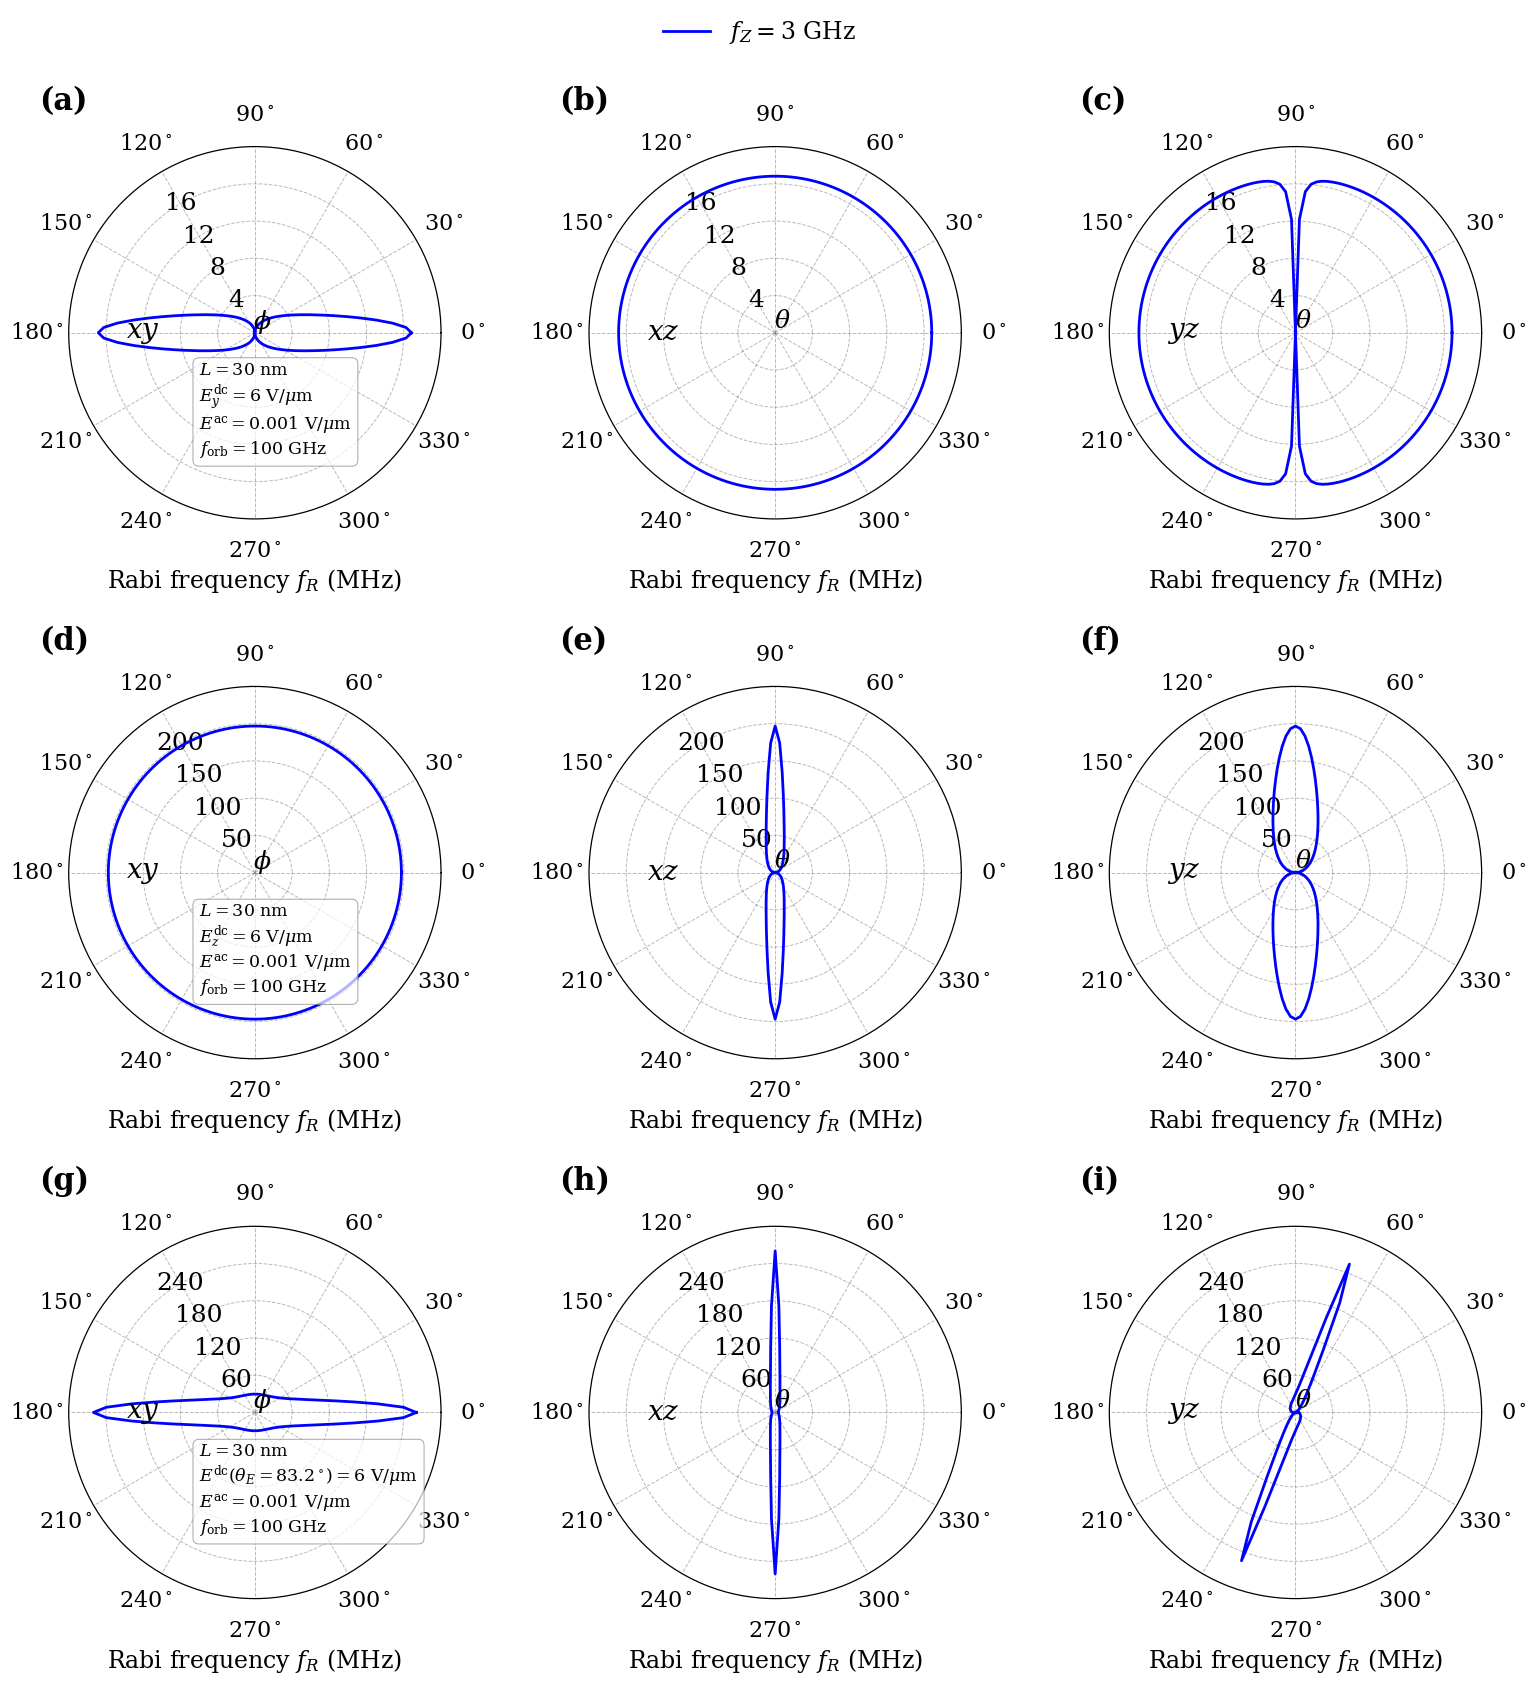

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator


# ==================================================
# Data-file structure
#
#  0: angle_deg
#
#  1: g_xy
#  2: B_xy_T
#  3: fR_xy_MHz
#
#  4: g_xz
#  5: B_xz_T
#  6: fR_xz_MHz
#
#  7: g_yz
#  8: B_yz_T
#  9: fR_yz_MHz
# ==================================================


def load_fixed_zeeman_data(filename):
    """Load and angle-sort one fixed-Zeeman angular-sweep data file."""

    data = np.loadtxt(filename, comments="#")

    if data.ndim != 2 or data.shape[1] < 10:
        raise ValueError(
            f"{filename} must contain at least 10 columns:\n"
            "angle, g_xy, B_xy, fR_xy, "
            "g_xz, B_xz, fR_xz, "
            "g_yz, B_yz, fR_yz"
        )

    result = {
        "angle": data[:, 0],
        "g_xy": data[:, 1],
        "B_xy": data[:, 2],
        "fR_xy": data[:, 3],
        "g_xz": data[:, 4],
        "B_xz": data[:, 5],
        "fR_xz": data[:, 6],
        "g_yz": data[:, 7],
        "B_yz": data[:, 8],
        "fR_yz": data[:, 9],
    }

    sorting_indices = np.argsort(result["angle"])
    return {
        key: values[sorting_indices]
        for key, values in result.items()
    }


def numerical_filename(fZ_GHz, E_dir):
    """Filename written by main_EDSR_fixed_Zeeman_angle_sweep.py:
    numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fZ}_E{dir}dc_{E}.dat
    (tries the int/float spellings of fZ and E, e.g. 5 / 5.0 and 6.0 / 6)."""
    fz_forms = {f"{fZ_GHz:g}", f"{float(fZ_GHz)}"}
    e_forms = {f"{float(E_dc_Vum)}", f"{E_dc_Vum:g}"}
    candidates = [
        data_dir / f"numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fz}_E{E_dir}dc_{e}.dat"
        for fz in sorted(fz_forms) for e in sorted(e_forms)
    ]
    for c in candidates:
        if c.is_file():
            return c
    return candidates[0]


def polar_curve(angle_deg, radial_values):
    """Convert degrees to radians and close a full-circle curve if necessary."""

    angle_rad = np.deg2rad(angle_deg)

    if len(angle_rad) > 1 and not np.isclose(
        angle_rad[-1] - angle_rad[0],
        2.0 * np.pi,
    ):
        angle_rad = np.append(angle_rad, angle_rad[0] + 2.0 * np.pi)
        radial_values = np.append(radial_values, radial_values[0])

    return angle_rad, radial_values


def add_radial_label(ax, label, fontsize=16, y=-0.13):
    """Radial-axis label centred below the polar panel."""
    ax.text(
        0.5, y, label,
        transform=ax.transAxes,
        fontsize=fontsize,
        horizontalalignment="center",
        verticalalignment="top",
    )


# ==================================================
# Load the target-fZ dataset before plotting
# ==================================================

# One row per case: "y" -> E_y^dc, "z" -> E_z^dc, a number -> E^dc at that angle (deg) from +y in the y-z plane
# (taken from the sphere map; uses load_from_sphere_map from the 3x3 cell above).
E_dc_dirs = ("y", "z", 83.2)


def case_label(E_dir):
    if isinstance(E_dir, str):
        return fr"E_{E_dir}^{{\mathrm{{dc}}}}"
    return fr"E^{{\mathrm{{dc}}}}(\theta_E={E_dir:g}^\circ)"


def case_tag(E_dir):
    return E_dir if isinstance(E_dir, str) else f"th{E_dir:g}"


datasets = {}
for E_dir in E_dc_dirs:
    filename = numerical_filename(target_fZ_GHz, E_dir) if isinstance(E_dir, str) else None
    if filename is not None and filename.is_file():
        loader = load_fixed_zeeman_data
    else:
        # no angle-sweep .dat file: fall back to the sphere map (y -> 0 deg, z -> 90 deg from +y)
        E_theta = {"y": 0.0, "z": 90.0}.get(E_dir, E_dir)
        filename = data_dir / f"EDSR_sphere_map_fz_{target_fZ_GHz:g}_Eth{E_theta:.2f}dc_{E_dc_Vum:g}.npz"
        loader = load_from_sphere_map

    if not filename.is_file():
        raise FileNotFoundError(
            f"Fixed-Zeeman data file not found: {filename}\n"
            "Check target_fZ_GHz, E_dc_Vum, E_dc_dirs, and data_dir."
        )

    datasets[E_dir] = loader(filename)
    print(f"Loaded f_Z = {target_fZ_GHz:g} GHz, {E_dir}: {filename}")


# ==================================================
# Plot settings
# ==================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.9,
    "font.size": 18,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

planes = ("xy", "xz", "yz")
plane_labels = (r"$xy$", r"$xz$", r"$yz$")
angle_labels = (r"$\phi$", r"$\theta$", r"$\theta$")
panel_tags = tuple(f"({chr(ord('a') + i)})" for i in range(3 * len(E_dc_dirs)))

color = "blue"


# ==================================================
# Radial range: common across the three planes of one direction
# (rows differ a lot in magnitude, so each row has its own scale)
# ==================================================

def radial_scale(dataset):
    all_rabi_values = [dataset[f"fR_{plane}"] for plane in planes]

    minimum_Rabi_frequency = min(np.nanmin(values) for values in all_rabi_values)
    maximum_Rabi_frequency = max(np.nanmax(values) for values in all_rabi_values)

    if not np.isfinite(maximum_Rabi_frequency) or maximum_Rabi_frequency <= 0.0:
        raise ValueError("The maximum Rabi frequency must be finite and positive.")

    if minimum_Rabi_frequency < 0.0:
        print(
            "Warning: negative Rabi-frequency values are present. "
            "The polar radial axis starts at zero, so those values are not visible."
        )

    candidate_ticks = MaxNLocator(nbins=5).tick_values(0.0, 1.10 * maximum_Rabi_frequency)
    candidate_ticks = candidate_ticks[candidate_ticks >= 0.0]

    radial_max = candidate_ticks[-1]
    radial_ticks = candidate_ticks[(candidate_ticks > 0.0) & (candidate_ticks < radial_max)]
    return radial_max, radial_ticks


# ==================================================
# Create the N x 3 polar comparison figure (one row per E^dc case)
# ==================================================

fig, axes = plt.subplots(
    len(E_dc_dirs),
    3,
    figsize=(15.5, 5.5 * len(E_dc_dirs)),
    subplot_kw={"projection": "polar"},
)

angular_ticks_deg = np.arange(0, 360, 30)
angular_ticks_rad = np.deg2rad(angular_ticks_deg)
angular_tick_labels = [
    rf"${angle}^\circ$"
    for angle in angular_ticks_deg
]

for row, E_dir in enumerate(E_dc_dirs):
    dataset = datasets[E_dir]
    radial_max, radial_ticks = radial_scale(dataset)

    for col, (ax, plane, plane_label, angle_label) in enumerate(zip(
        axes[row],
        planes,
        plane_labels,
        angle_labels,
    )):
        panel_tag = panel_tags[3 * row + col]
        angle_rad, fR = polar_curve(
            dataset["angle"],
            dataset[f"fR_{plane}"],
        )

        ax.plot(
            angle_rad,
            fR,
            color=color,
            linewidth=2.0,
            label=fr"$f_Z={target_fZ_GHz:g}$ GHz",
            zorder=2,
        )

        # Put 0 degrees on the positive horizontal axis; angles increase CCW.
        ax.set_theta_zero_location("E")
        ax.set_theta_direction(1)
        ax.set_xticks(angular_ticks_rad)
        ax.set_xticklabels(angular_tick_labels)

        # A common radial scale (per row) enables direct comparison among the three planes.
        ax.set_ylim(0.0, radial_max)
        ax.set_yticks(radial_ticks)
        ax.set_rlabel_position(120)
        add_radial_label(ax, r"Rabi frequency $f_R$ (MHz)", fontsize=17)

        # Larger pad keeps the angle labels clear of the circular boundary.
        ax.tick_params(axis="x", labelsize=16, pad=16)
        ax.tick_params(axis="y", labelsize=18, pad=7)

        # Keep the radial labels horizontal.
        ax.set_yticklabels(
            [f"{tick:g}" for tick in radial_ticks],
            rotation=0,
            rotation_mode="default",
            horizontalalignment="center",
            verticalalignment="center",
        )

        ax.grid(
            True,
            linestyle="--",
            linewidth=0.7,
            color="gray",
            alpha=0.55,
        )

        ax.text(
            0.20,
            0.50,
            plane_label,
            transform=ax.transAxes,
            fontsize=20,
            fontweight="bold",
            horizontalalignment="center",
            verticalalignment="center",
        )

        ax.text(
            0.52,
            0.53,
            angle_label,
            transform=ax.transAxes,
            fontsize=18,
            horizontalalignment="center",
            verticalalignment="center",
        )

        # Panel label (a), (b), (c) at the upper-left of each panel.
        ax.text(
            -0.08,
            1.08,
            panel_tag,
            transform=ax.transAxes,
            fontsize=22,
            fontweight="bold",
            horizontalalignment="left",
            verticalalignment="bottom",
        )


# ==================================================
# Parameter box and one common fZ legend
# ==================================================

for row, E_dir in enumerate(E_dc_dirs):
    parameter_text = (
        fr"$L={L_nm:g}$ nm" "\n"
        fr"${case_label(E_dir)}={E_dc_Vum:g}$ V/$\mu$m" "\n"
        fr"$E^{{\mathrm{{ac}}}}={E_ac_Vum:g}$ V/$\mu$m" "\n"
        fr"$f_{{\mathrm{{orb}}}}={f_orb_GHz:g}$ GHz"
    )

    axes[row, 0].text(
        0.35,
        0.29,
        parameter_text,
        transform=axes[row, 0].transAxes,
        fontsize=12.5,
        horizontalalignment="left",
        verticalalignment="center",
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": "white",
            "edgecolor": "gray",
            "linewidth": 0.7,
            "alpha": 0.7,
        },
        zorder=5,
    )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    frameon=False,
    fontsize=17,
)


# ==================================================
# Layout and save
# ==================================================

fig.subplots_adjust(
    left=0.05,
    right=0.97,
    bottom=0.05,
    top=0.93,
    wspace=0.35,
    hspace=0.45,
)

fz_tag = f"{target_fZ_GHz:g}_Edc_{E_dc_Vum:g}_{'_'.join(case_tag(e) for e in E_dc_dirs)}"
output_stem = output_dir / f"fixed_Zeeman_comparison_fz_{fz_tag}_polar_{len(E_dc_dirs)}x3"

fig.savefig(f"{output_stem}.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{output_stem}.pdf", bbox_inches="tight")
fig.savefig(f"{output_stem}.svg", bbox_inches="tight")

print(f"Saved polar comparison as {output_stem}.png/.pdf/.svg")
plt.show()


In [101]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.ticker import MaxNLocator


# # ==================================================
# # Numerical input file
# # ==================================================

# def numerical_filename(fZ_GHz):
#     """Filename written by main_EDSR_fixed_Zeeman_angle_sweep.py:
#     numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fZ}_E{dir}dc_{E}.dat
#     (tries the int/float spellings of fZ and E, e.g. 5 / 5.0 and 6.0 / 6)."""
#     fz_forms = {f"{fZ_GHz:g}", f"{float(fZ_GHz)}"}
#     e_forms = {f"{float(E_dc_Vum)}", f"{E_dc_Vum:g}"}
#     candidates = [
#         data_dir / f"numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fz}_E{E_dc_dir}dc_{e}.dat"
#         for fz in sorted(fz_forms) for e in sorted(e_forms)
#     ]
#     for c in candidates:
#         if c.is_file():
#             return c
#     return candidates[0]


# numerical_file = numerical_filename(target_fZ_GHz)

# # Expected data-file structure:
# #
# # 0: angle_deg
# #
# # 1: g_xy
# # 2: B_xy_T
# # 3: fR_xy_MHz
# #
# # 4: g_xz
# # 5: B_xz_T
# # 6: fR_xz_MHz
# #
# # 7: g_yz
# # 8: B_yz_T
# # 9: fR_yz_MHz


# def load_fixed_zeeman_data(filename):
#     """Load fixed-Zeeman numerical angular-sweep data."""

#     data = np.loadtxt(
#         filename,
#         comments="#",
#     )

#     if data.ndim != 2 or data.shape[1] < 10:
#         raise ValueError(
#             f"{filename} must contain at least 10 columns:\n"
#             "angle, g_xy, B_xy, fR_xy, "
#             "g_xz, B_xz, fR_xz, "
#             "g_yz, B_yz, fR_yz"
#         )

#     return {
#         "angle": data[:, 0],
#         "g_xy": data[:, 1],
#         "B_xy": data[:, 2],
#         "fR_xy": data[:, 3],
#         "g_xz": data[:, 4],
#         "B_xz": data[:, 5],
#         "fR_xz": data[:, 6],
#         "g_yz": data[:, 7],
#         "B_yz": data[:, 8],
#         "fR_yz": data[:, 9],
#     }


# def add_radial_label(ax, label, fontsize=16, y=-0.13):
#     """Radial-axis label centred below the polar panel."""
#     ax.text(
#         0.5, y, label,
#         transform=ax.transAxes,
#         fontsize=fontsize,
#         horizontalalignment="center",
#         verticalalignment="top",
#     )


# # ==================================================
# # Load and sort numerical data
# # ==================================================

# numerical = load_fixed_zeeman_data(numerical_file)

# print(f"Loaded numerical data: {numerical_file}")
# print(
#     "Angular range: "
#     f"{numerical['angle'].min():g}° to "
#     f"{numerical['angle'].max():g}°"
# )

# # Sort the data by increasing angle
# sorting_indices = np.argsort(numerical["angle"])

# for key in numerical:
#     numerical[key] = numerical[key][sorting_indices]

# # Convert degrees to radians
# angle_rad = np.deg2rad(numerical["angle"])


# # ==================================================
# # Plot settings
# # ==================================================

# plt.rcParams.update({
#     "font.family": "serif",
#     "mathtext.fontset": "dejavuserif",
#     "axes.linewidth": 0.9,
#     "font.size": 15,
#     "xtick.direction": "in",
#     "ytick.direction": "in",
# })


# # ==================================================
# # g-factor data for the three planes
# # ==================================================

# g_data = [
#     numerical["g_xy"],
#     numerical["g_xz"],
#     numerical["g_yz"],
# ]

# plane_labels = [
#     r"$xy$",
#     r"$xz$",
#     r"$yz$",
# ]

# angle_labels = [
#     r"$\phi$",
#     r"$\theta$",
#     r"$\theta$",
# ]

# line_colors = [
#     "#2166ac",
#     "#2166ac",
#     "#2166ac",
# ]


# # ==================================================
# # Independent radial ranges for the three panels
# # ==================================================

# radial_maxima = []
# radial_ticks_list = []

# for plane, g_eff in zip(plane_labels, g_data):

#     if not np.any(np.isfinite(g_eff)):
#         raise ValueError(
#             f"No finite g-factor values were found for the {plane} plane."
#         )

#     maximum_g = np.nanmax(g_eff)

#     if maximum_g <= 0.0:
#         raise ValueError(
#             f"The maximum g factor for the {plane} plane must be positive."
#         )

#     # Choose clean radial ticks independently for each panel
#     radial_locator = MaxNLocator(
#         nbins=5,
#         min_n_ticks=3,
#     )

#     candidate_ticks = radial_locator.tick_values(
#         0.0,
#         1.08 * maximum_g,
#     )

#     candidate_ticks = candidate_ticks[
#         candidate_ticks >= 0.0
#     ]

#     radial_max = candidate_ticks[-1]

#     # Do not label zero or the outer boundary
#     radial_ticks = candidate_ticks[
#         (candidate_ticks > 0.0)
#         & (candidate_ticks < radial_max)
#     ]

#     radial_maxima.append(radial_max)
#     radial_ticks_list.append(radial_ticks)

#     print(
#         f"{plane} plane: "
#         f"maximum g = {maximum_g:.6g}, "
#         f"radial range = 0 to {radial_max:g}"
#     )


# # ==================================================
# # Create the 1 × 3 polar figure
# # ==================================================

# fig, axes = plt.subplots(
#     1,
#     3,
#     figsize=(15.5, 5.8),
#     subplot_kw={"projection": "polar"},
# )


# # ==================================================
# # Full-circle angular ticks
# # ==================================================

# angular_ticks_deg = np.arange(
#     0,
#     360,
#     30,
# )

# angular_ticks_rad = np.deg2rad(
#     angular_ticks_deg
# )

# angular_tick_labels = [
#     rf"${angle}^\circ$"
#     for angle in angular_ticks_deg
# ]


# # ==================================================
# # Plot effective g factors
# # ==================================================

# for (
#     ax,
#     g_eff,
#     plane,
#     angle_label,
#     color,
#     radial_max,
#     radial_ticks,
# ) in zip(
#     axes,
#     g_data,
#     plane_labels,
#     angle_labels,
#     line_colors,
#     radial_maxima,
#     radial_ticks_list,
# ):

#     # Numerical g-factor curve
#     ax.plot(
#         angle_rad,
#         g_eff,
#         color=color,
#         linewidth=2.4,
#         zorder=2,
#     )

#     # Optional numerical points
#     # ax.scatter(
#     #     angle_rad,
#     #     g_eff,
#     #     s=22,
#     #     color=color,
#     #     edgecolor="white",
#     #     linewidth=0.45,
#     #     zorder=3,
#     # )

#     # Put 0° on the positive horizontal axis
#     ax.set_theta_zero_location("E")

#     # Angles increase counterclockwise
#     ax.set_theta_direction(1)

#     # Angular ticks
#     ax.set_xticks(angular_ticks_rad)
#     ax.set_xticklabels(angular_tick_labels)

#     # Independent radial scale
#     ax.set_ylim(
#         0.0,
#         radial_max,
#     )

#     ax.set_yticks(radial_ticks)

#     # Format the radial values without unnecessary zeros
#     ax.set_yticklabels([
#         f"{tick:g}"
#         for tick in radial_ticks
#     ])

#     # Position radial labels in the upper-left quadrant
#     ax.set_rlabel_position(135)
#     add_radial_label(ax, r"Effective $g$ factor $g_{\mathrm{eff}}$")

#     ax.tick_params(
#         axis="x",
#         labelsize=12,
#         pad=7,
#     )

#     ax.tick_params(
#         axis="y",
#         labelsize=11,
#         pad=3,
#     )

#     ax.grid(
#         True,
#         linestyle="--",
#         linewidth=0.7,
#         color="gray",
#         alpha=0.55,
#     )

#     # Plane label inside the plot
#     ax.text(
#         0.20,
#         0.50,
#         plane,
#         transform=ax.transAxes,
#         fontsize=17,
#         fontweight="bold",
#         horizontalalignment="center",
#         verticalalignment="center",
#     )

#     # Angular-variable label near the center
#     ax.text(
#         0.52,
#         0.53,
#         angle_label,
#         transform=ax.transAxes,
#         fontsize=16,
#         horizontalalignment="center",
#         verticalalignment="center",
#     )


# # ==================================================
# # Parameter box inside the first panel
# # ==================================================

# parameter_text = (
#     fr"$L={L_nm:g}$ nm" "\n"
#     fr"$f_Z={target_fZ_GHz:g}$ GHz" "\n"
#     fr"$E_{E_dc_dir}^{{\mathrm{{dc}}}}={E_dc_Vum:g}$ V/$\mu$m"
# )

# axes[0].text(
#     0.34,
#     0.27,
#     parameter_text,
#     transform=axes[0].transAxes,
#     fontsize=10.5,
#     horizontalalignment="left",
#     verticalalignment="center",
#     bbox={
#         "boxstyle": "round,pad=0.35",
#         "facecolor": "white",
#         "edgecolor": "gray",
#         "linewidth": 0.7,
#         "alpha": 0.88,
#     },
#     zorder=5,
# )


# # ==================================================
# # Layout
# # ==================================================

# fig.subplots_adjust(
#     left=0.04,
#     right=0.98,
#     bottom=0.14,
#     top=0.96,
#     wspace=0.30,
# )


# # ==================================================
# # Save the figure
# # ==================================================

# fig.savefig(
#     f"export_data/numerical_gfactor_fixed_Zeeman_polar_1x3_fz_{target_fZ_GHz:g}_E{E_dc_dir}dc_{E_dc_Vum:g}.png",
#     dpi=300,
#     bbox_inches="tight",
# )

# fig.savefig(
#     f"export_data/numerical_gfactor_fixed_Zeeman_polar_1x3_fz_{target_fZ_GHz:g}_E{E_dc_dir}dc_{E_dc_Vum:g}.pdf",
#     bbox_inches="tight",
# )

# fig.savefig(
#     f"export_data/numerical_gfactor_fixed_Zeeman_polar_1x3_fz_{target_fZ_GHz:g}_E{E_dc_dir}dc_{E_dc_Vum:g}.svg",
#     bbox_inches="tight",
# )

# plt.show()

In [102]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.ticker import MaxNLocator


# # ==================================================
# # Numerical input file
# # ==================================================

# def numerical_filename(fZ_GHz):
#     """Filename written by main_EDSR_fixed_Zeeman_angle_sweep.py:
#     numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fZ}_E{dir}dc_{E}.dat
#     (tries the int/float spellings of fZ and E, e.g. 5 / 5.0 and 6.0 / 6)."""
#     fz_forms = {f"{fZ_GHz:g}", f"{float(fZ_GHz)}"}
#     e_forms = {f"{float(E_dc_Vum)}", f"{E_dc_Vum:g}"}
#     candidates = [
#         data_dir / f"numerical_Rabi_fixed_Zeeman_angle_sweep_fz_{fz}_E{E_dc_dir}dc_{e}.dat"
#         for fz in sorted(fz_forms) for e in sorted(e_forms)
#     ]
#     for c in candidates:
#         if c.is_file():
#             return c
#     return candidates[0]


# numerical_file = numerical_filename(target_fZ_GHz)

# # Expected data-file structure:
# #
# # 0: angle_deg
# #
# # 1: g_xy
# # 2: B_xy_T
# # 3: fR_xy_MHz
# #
# # 4: g_xz
# # 5: B_xz_T
# # 6: fR_xz_MHz
# #
# # 7: g_yz
# # 8: B_yz_T
# # 9: fR_yz_MHz


# def load_fixed_zeeman_data(filename):
#     """Load fixed-Zeeman numerical angular-sweep data."""

#     data = np.loadtxt(
#         filename,
#         comments="#",
#     )

#     if data.ndim != 2 or data.shape[1] < 10:
#         raise ValueError(
#             f"{filename} must contain at least 10 columns:\n"
#             "angle, g_xy, B_xy, fR_xy, "
#             "g_xz, B_xz, fR_xz, "
#             "g_yz, B_yz, fR_yz"
#         )

#     return {
#         "angle": data[:, 0],
#         "g_xy": data[:, 1],
#         "B_xy": data[:, 2],
#         "fR_xy": data[:, 3],
#         "g_xz": data[:, 4],
#         "B_xz": data[:, 5],
#         "fR_xz": data[:, 6],
#         "g_yz": data[:, 7],
#         "B_yz": data[:, 8],
#         "fR_yz": data[:, 9],
#     }


# def add_radial_label(ax, label, fontsize=16, y=-0.13):
#     """Radial-axis label centred below the polar panel."""
#     ax.text(
#         0.5, y, label,
#         transform=ax.transAxes,
#         fontsize=fontsize,
#         horizontalalignment="center",
#         verticalalignment="top",
#     )


# # ==================================================
# # Load and sort numerical data
# # ==================================================

# numerical = load_fixed_zeeman_data(numerical_file)

# print(f"Loaded numerical data: {numerical_file}")
# print(
#     "Angular range: "
#     f"{numerical['angle'].min():g}° to "
#     f"{numerical['angle'].max():g}°"
# )

# sorting_indices = np.argsort(numerical["angle"])

# for key in numerical:
#     numerical[key] = numerical[key][sorting_indices]

# # Convert degrees to radians
# angle_rad = np.deg2rad(numerical["angle"])


# # ==================================================
# # Plot settings
# # ==================================================

# plt.rcParams.update({
#     "font.family": "serif",
#     "mathtext.fontset": "dejavuserif",
#     "axes.linewidth": 0.9,
#     "font.size": 15,
#     "xtick.direction": "in",
#     "ytick.direction": "in",
# })


# # ==================================================
# # Magnetic-field data
# # ==================================================

# B_data = [
#     numerical["B_xy"],
#     numerical["B_xz"],
#     numerical["B_yz"],
# ]

# plane_labels = [
#     r"$xy$",
#     r"$xz$",
#     r"$yz$",
# ]

# angle_labels = [
#     r"$\phi$",
#     r"$\theta$",
#     r"$\theta$",
# ]

# line_colors = [
#     "#b2182b",
#     "#b2182b",
#     "#b2182b",
# ]


# # ==================================================
# # Independent radial ranges for the three panels
# # ==================================================

# radial_maxima = []
# radial_ticks_list = []

# for plane, B_eff in zip(plane_labels, B_data):

#     if not np.any(np.isfinite(B_eff)):
#         raise ValueError(
#             f"No finite magnetic-field values were found "
#             f"for the {plane} plane."
#         )

#     maximum_B = np.nanmax(B_eff)

#     if maximum_B <= 0.0:
#         raise ValueError(
#             f"The maximum magnetic field for the "
#             f"{plane} plane must be positive."
#         )

#     radial_locator = MaxNLocator(
#         nbins=5,
#         min_n_ticks=3,
#     )

#     # Add a small amount of space outside the curve
#     candidate_ticks = radial_locator.tick_values(
#         0.0,
#         1.08 * maximum_B,
#     )

#     candidate_ticks = candidate_ticks[
#         candidate_ticks >= 0.0
#     ]

#     radial_max = candidate_ticks[-1]

#     # Exclude zero and the outer boundary from the labels
#     radial_ticks = candidate_ticks[
#         (candidate_ticks > 0.0)
#         & (candidate_ticks < radial_max)
#     ]

#     radial_maxima.append(radial_max)
#     radial_ticks_list.append(radial_ticks)

#     print(
#         f"{plane} plane: "
#         f"maximum B = {maximum_B:.6g} T, "
#         f"radial range = 0 to {radial_max:g} T"
#     )


# # ==================================================
# # Create the 1 × 3 polar figure
# # ==================================================

# fig, axes = plt.subplots(
#     1,
#     3,
#     figsize=(15.5, 5.8),
#     subplot_kw={"projection": "polar"},
# )


# # ==================================================
# # Full-circle angular ticks
# # ==================================================

# angular_ticks_deg = np.arange(
#     0,
#     360,
#     30,
# )

# angular_ticks_rad = np.deg2rad(
#     angular_ticks_deg
# )

# angular_tick_labels = [
#     rf"${angle}^\circ$"
#     for angle in angular_ticks_deg
# ]


# # ==================================================
# # Plot magnetic-field magnitude
# # ==================================================

# for (
#     ax,
#     B_eff,
#     plane,
#     angle_label,
#     color,
#     radial_max,
#     radial_ticks,
# ) in zip(
#     axes,
#     B_data,
#     plane_labels,
#     angle_labels,
#     line_colors,
#     radial_maxima,
#     radial_ticks_list,
# ):

#     # Numerical magnetic-field curve
#     ax.plot(
#         angle_rad,
#         B_eff,
#         color=color,
#         linewidth=2.4,
#         zorder=2,
#     )

#     # Optional numerical data points
#     # ax.scatter(
#     #     angle_rad,
#     #     B_eff,
#     #     s=22,
#     #     color=color,
#     #     edgecolor="white",
#     #     linewidth=0.45,
#     #     zorder=3,
#     # )

#     # Put 0° on the positive horizontal axis
#     ax.set_theta_zero_location("E")

#     # Angles increase counterclockwise
#     ax.set_theta_direction(1)

#     # Angular ticks
#     ax.set_xticks(angular_ticks_rad)
#     ax.set_xticklabels(angular_tick_labels)

#     # Independent radial scale
#     ax.set_ylim(
#         0.0,
#         radial_max,
#     )

#     ax.set_yticks(radial_ticks)

#     # Format radial values cleanly
#     ax.set_yticklabels([
#         f"{tick:g}"
#         for tick in radial_ticks
#     ])

#     # Position radial labels in the upper-left quadrant
#     ax.set_rlabel_position(135)
#     add_radial_label(ax, r"Magnetic field $B$ (T)")

#     ax.tick_params(
#         axis="x",
#         labelsize=12,
#         pad=7,
#     )

#     ax.tick_params(
#         axis="y",
#         labelsize=11,
#         pad=3,
#     )

#     ax.grid(
#         True,
#         linestyle="--",
#         linewidth=0.7,
#         color="gray",
#         alpha=0.55,
#     )

#     # Plane label
#     ax.text(
#         0.20,
#         0.50,
#         plane,
#         transform=ax.transAxes,
#         fontsize=17,
#         fontweight="bold",
#         horizontalalignment="center",
#         verticalalignment="center",
#     )

#     # Angular-variable label
#     ax.text(
#         0.52,
#         0.53,
#         angle_label,
#         transform=ax.transAxes,
#         fontsize=16,
#         horizontalalignment="center",
#         verticalalignment="center",
#     )


# # ==================================================
# # Parameter box inside the first panel
# # ==================================================

# parameter_text = (
#     fr"$L={L_nm:g}$ nm" "\n"
#     fr"$f_Z={target_fZ_GHz:g}$ GHz" "\n"
#     fr"$E_{E_dc_dir}^{{\mathrm{{dc}}}}={E_dc_Vum:g}$ V/$\mu$m"
# )

# axes[0].text(
#     0.34,
#     0.27,
#     parameter_text,
#     transform=axes[0].transAxes,
#     fontsize=10.5,
#     horizontalalignment="left",
#     verticalalignment="center",
#     bbox={
#         "boxstyle": "round,pad=0.35",
#         "facecolor": "white",
#         "edgecolor": "gray",
#         "linewidth": 0.7,
#         "alpha": 0.88,
#     },
#     zorder=5,
# )


# # ==================================================
# # Layout
# # ==================================================

# fig.subplots_adjust(
#     left=0.04,
#     right=0.98,
#     bottom=0.14,
#     top=0.96,
#     wspace=0.30,
# )


# # ==================================================
# # Save the figure
# # ==================================================

# fig.savefig(
#     f"export_data/numerical_Bfield_fixed_Zeeman_polar_1x3_fz_{target_fZ_GHz:g}_E{E_dc_dir}dc_{E_dc_Vum:g}.png",
#     dpi=300,
#     bbox_inches="tight",
# )

# fig.savefig(
#     f"export_data/numerical_Bfield_fixed_Zeeman_polar_1x3_fz_{target_fZ_GHz:g}_E{E_dc_dir}dc_{E_dc_Vum:g}.pdf",
#     bbox_inches="tight",
# )

# fig.savefig(
#     f"export_data/numerical_Bfield_fixed_Zeeman_polar_1x3_fz_{target_fZ_GHz:g}_E{E_dc_dir}dc_{E_dc_Vum:g}.svg",
#     bbox_inches="tight",
# )

# plt.show()